# TP 1 — Construire un pipeline NLP classique

**Cours NLP et Transformers — CY Tech**

---

## Avant de commencer

**Faites tout de suite : `Fichier` → `Enregistrer une copie dans Drive`.**
Sans cela vous travaillez sur une copie temporaire et vous perdrez tout en fermant l'onglet.

## Objectif

Construire un pipeline de classification de texte **complet et correctement évalué**, de bout en bout :

`texte brut → prétraitement → représentation → modèle → mesure`

Le but n'est pas d'obtenir le meilleur score. Le but est que **chaque décision du pipeline soit justifiée** et que le score annoncé soit crédible.

## Ce qui est attendu

1. Un jeu de données étiqueté construit à partir du corpus brut
2. Un prétraitement et une représentation TF–IDF
3. Une **baseline** avant tout modèle
4. **Au moins deux modèles** de machine learning comparés
5. Une évaluation avec accuracy, précision, rappel, F1 et matrice de confusion
6. Une **analyse des erreurs** rédigée (partie 8) — c'est la partie la plus importante

## Les deux erreurs qui coûtent des points

- Vectoriser **avant** de découper train/test → fuite de données, tout le TP est invalidé
- Afficher une matrice de confusion sans la commenter

---

## 0. Environnement

Rien à installer : tout est déjà présent dans Colab. Exécutez simplement la cellule.

In [ ]:
import re
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environnement prêt.")

Environnement prêt.


## 1. Charger le corpus

Le corpus **Tiny Shakespeare** : environ 40 000 lignes extraites de plusieurs pièces de Shakespeare.

C'est du **texte brut, sans aucune étiquette**. C'est volontaire : une grande partie du travail d'un data scientist consiste à transformer une matière première non structurée en un problème d'apprentissage bien posé.

In [ ]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

texte = urllib.request.urlopen(URL).read().decode("utf-8")

print(f"{len(texte):,} caractères")
print(f"{len(texte.splitlines()):,} lignes")
print("\n--- 300 premiers caractères ---\n")
print(texte[:300])

1,115,394 caractères
40,000 lignes

--- 300 premiers caractères ---

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 2. Observer la structure avant de coder

**Avant d'écrire quoi que ce soit, regardez vos données.** C'est la première règle du métier, et c'est celle qu'on saute le plus souvent.

Affichez un extrait plus long et répondez aux questions ci-dessous.

In [ ]:
print(texte[1000:2500])

Second Citizen:
Would you proceed especially against Caius Marcius?

All:
Against him first: he's a very dog to the commonalty.

Second Citizen:
Consider you what services he has done for his country?

First Citizen:
Very well; and could be content to give him good
report fort, but that he pays himself with being proud.

Second Citizen:
Nay, but speak not maliciously.

First Citizen:
I say unto you, what he hath done famously, he did
it to that end: though soft-conscienced men can be
content to say it was for his country he did it to
please his mother and to be partly proud; which he
is, even till the altitude of his virtue.

Second Citizen:
What he cannot help in his nature, you account a
vice in him. You must in no way say he is covetous.

First Citizen:
If I must not, I need not be barren of accusations;
he hath faults, with surplus, to tire in repetition.
What shouts are these? The other side o' the city
is risen: why stay we prating here? to the Capitol!

All:
Come, come.

First C

**Questions — répondez ici avant de continuer :**

1. Quelle est la structure répétitive du texte ? Qu'est-ce qui sépare deux blocs ?
2. Quelle information exploitable comme étiquette est déjà présente dans le texte ?
3. Cette étiquette existait-elle vraiment, ou faut-il l'annoter à la main ?

> *Vos réponses :*
>
> 1. Le texte est une suite de **blocs séparés par une ligne vide**. Chaque bloc commence par une ligne d'en-tête `NOM DU PERSONNAGE:` (nom + deux-points, seul sur sa ligne), suivie d'une ou plusieurs lignes de texte : la réplique. Une réplique peut s'étaler sur plusieurs lignes (vers de 8-10 syllabes), donc le saut de ligne simple ne sépare *pas* deux répliques, seule la ligne vide le fait.
>
> 2. **Le nom du locuteur** (l'en-tête avant le « : ») est directement exploitable comme étiquette : chaque réplique est associée à celui qui la prononce. On peut donc poser une tâche de classification « qui parle ? » (attribution du locuteur).
>
> 3. Il n'y a **aucune annotation manuelle** : le corpus ne contient pas de colonne « label » distincte, mais l'étiquette est déjà écrite dans la structure du texte (convention de mise en page d'une pièce de théâtre). Un simple parsing suffit pour l'extraire (cf. partie 3). Seule précaution : 128 blocs sur 7 222 sont des en-têtes **sans réplique** (ex. `GLOUCESTER:` suivi directement d'un autre locuteur) ; la fonction de parsing les écarte à raison (`len(parties) > 1`), ce qui laisse 7 094 répliques.

---

💡 **Le point à retenir.** Vous venez de trouver une cible qui existait déjà dans les données, sans le moindre annotateur humain. C'est exactement le principe de l'**apprentissage auto-supervisé** vu en cours : on fabrique le signal à partir de la structure du texte lui-même. C'est le mécanisme qui rend possible l'entraînement des grands modèles de langage.

## 3. Construire le jeu de données étiqueté

La fonction de parsing vous est donnée : ce n'est pas l'objet du TP, et une regex mal réglée vous ferait perdre une heure.

**Lisez-la quand même**, vous devrez justifier ce qu'elle garde et ce qu'elle jette.

In [ ]:
def parser_repliques(txt: str) -> pd.DataFrame:
    """Découpe le corpus en répliques (locuteur, texte).

    Format attendu dans le corpus :

        NOM DU LOCUTEUR:
        première ligne de la réplique
        seconde ligne de la réplique

    Les blocs sont séparés par une ligne vide.
    """
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

print(f"{len(df):,} répliques extraites")
print(f"{df['locuteur'].nunique()} locuteurs distincts")
df.head(10)

7,094 répliques extraites
297 locuteurs distincts


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."
5,All,"We know't, we know't."
6,First Citizen,"Let us kill him, and we'll have corn at our ow..."
7,All,"No more talking on't; let it be done: away, away!"
8,Second Citizen,"One word, good citizens."
9,First Citizen,"We are accounted poor citizens, the patricians..."


### 3.1 Explorer la distribution

Avant de choisir votre tâche, il faut savoir à quoi ressemble la distribution des classes.

locuteur
GLOUCESTER           211
DUKE VINCENTIO       189
MENENIUS             161
ROMEO                160
PETRUCHIO            155
CORIOLANUS           148
KING RICHARD III     137
ISABELLA             127
LEONTES              124
JULIET               124
SICINIUS             117
KING EDWARD IV       109
QUEEN ELIZABETH      105
LUCIO                101
WARWICK               98
KING RICHARD II       98
BRUTUS                91
HENRY BOLINGBROKE     90
TRANIO                90
BUCKINGHAM            89
Name: count, dtype: int64

Médiane : 14 mots | Moyenne : 27.2 mots
Répliques de moins de 5 mots : 13.5% | moins de 10 mots : 39.4%
Locuteurs avec moins de 10 répliques : 152 / 297


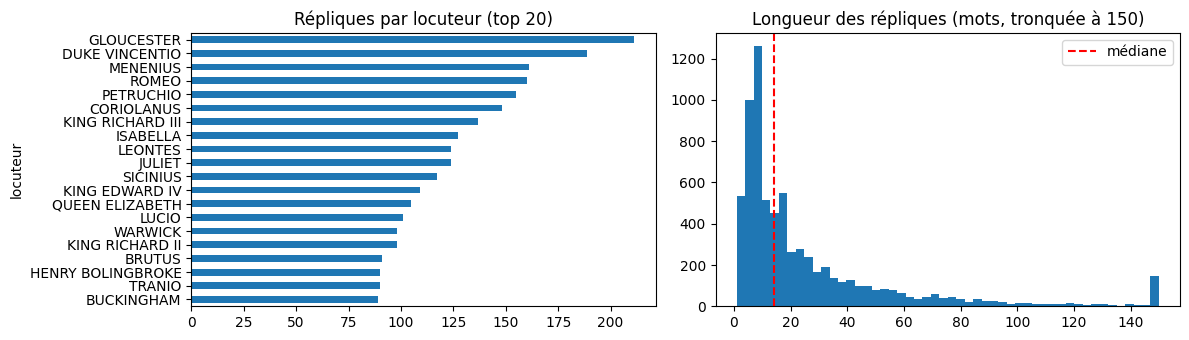

In [ ]:
# 20 locuteurs les plus fréquents
print(df['locuteur'].value_counts().head(20))

# Longueur des répliques (en mots)
df['nb_mots'] = df['replique'].str.split().str.len()
print(f"\nMédiane : {df['nb_mots'].median():.0f} mots | Moyenne : {df['nb_mots'].mean():.1f} mots")
print(f"Répliques de moins de 5 mots : {(df['nb_mots'] < 5).mean():.1%} | moins de 10 mots : {(df['nb_mots'] < 10).mean():.1%}")
print(f"Locuteurs avec moins de 10 répliques : {(df['locuteur'].value_counts() < 10).sum()} / {df['locuteur'].nunique()}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df['locuteur'].value_counts().head(20).plot.barh(ax=ax[0]); ax[0].invert_yaxis(); ax[0].set_title("Répliques par locuteur (top 20)")
ax[1].hist(df['nb_mots'].clip(upper=150), bins=50); ax[1].set_title("Longueur des répliques (mots, tronquée à 150)")
ax[1].axvline(df['nb_mots'].median(), color='red', ls='--', label='médiane'); ax[1].legend()
plt.tight_layout(); plt.show()

**Questions :**

1. La distribution des locuteurs est-elle équilibrée ? Que se passerait-il si vous gardiez les 297 locuteurs ?
2. Quelle est la longueur médiane d'une réplique ? Est-ce beaucoup pour de la classification de texte ?
3. Quelle conséquence cette longueur aura-t-elle sur votre vecteur TF–IDF ?

> **1. Équilibre.** Non, très déséquilibrée : le plus bavard (GLOUCESTER) a 211 répliques, et **152 locuteurs sur 297 en ont moins de 10**. Si je gardais les 297 classes, la majorité des classes n'aurait que quelques exemples : impossible de bien les apprendre, impossible d'en avoir dans chaque split, un F1 macro dominé par des classes quasi vides, et une accuracy qui ne reflèterait que les 10-20 gros locuteurs.
>
> **2. Longueur.** Médiane de **14 mots** (moyenne 27, très tirée vers le haut par quelques longues tirades, max 578). 13,5 % des répliques font moins de 5 mots, 39 % moins de 10. C'est **très court** pour de la classification de texte (un avis produit ou un article fait plutôt 50 à plusieurs centaines de mots) : très peu de signal par exemple.
>
> **3. Conséquence sur TF–IDF.** Chaque vecteur n'aura que quelques dizaines de composantes non nulles (≈ 34 termes, mots et bigrammes, par réplique en moyenne dans mon vocabulaire final) sur plusieurs milliers de colonnes. Beaucoup de répliques ne partagent presque aucun mot avec le reste du corpus, la norme L2 est fixée par très peu de termes, et un seul mot rare peut peser lourd. Les scores seront donc plafonnés et bruités ; filtrer les répliques les plus courtes est justifié.

## 4. Définir la tâche

À vous de poser le problème. Vous devez décider :

- **combien de locuteurs** vous gardez (le nombre de classes) ;
- s'il faut **filtrer les répliques trop courtes**, et à partir de quel seuil ;
- si vos classes sont suffisamment **équilibrées** pour que l'accuracy ait un sens.

Il n'y a pas une seule bonne réponse. Il y a des choix, et ils doivent être **justifiés et écrits**.

> **Votre choix et sa justification :**
>
> - Nombre de locuteurs retenus : **5** (GLOUCESTER, DUKE VINCENTIO, ROMEO, PETRUCHIO, MENENIUS)
> - Seuil de longueur minimale : **5 mots**
> - Pourquoi :
>   - *5 classes* : ce sont les 5 plus fréquents, tous avec ≥ 126 répliques exploitables ; assez d'exemples par classe pour en avoir ~25-40 dans le test. Au-delà (testé : 8 puis 10), les classes suivantes sont plus petites et les scores s'effondrent (voir 9.3), ce qui rend l'analyse d'erreurs moins lisible ; je garde 10 locuteurs comme extension.
>   - *Seuil de 5 mots* : on écarte les « Ay. », « Come, come. », « Well said! » qui n'ont aucune information stylistique et qui appartiendraient à n'importe quel personnage. Je n'ai pas pris 10 mots : j'ai testé (scores plus élevés) mais cela retirerait ≈ 30 % des exemples et ferait tomber le jeu à 550 exemples, avec un test de ~110 répliques seulement. 5 mots est un compromis entre qualité du signal et taille des données. **Transparence :** pour choisir N et le seuil, j'ai comparé le score de plusieurs configurations (N = 5, 8, 10 ; seuil = 0, 5, 10) sur un test de départ ; la décision finale repose surtout sur la taille des données et la lisibilité de l'analyse (le seuil de 10 mots donnait d'ailleurs de meilleurs scores, je ne l'ai pas retenu), mais ce choix de la tâche a vu des scores de test, ce qui peut introduire un très léger optimisme.
>   - *Équilibre* : après filtrage la classe majoritaire pèse 25,8 % (une classe parfaitement équilibrée donnerait 20 %) : déséquilibre **modéré**. L'accuracy reste interprétable (baseline 26 %), mais je reporte aussi le F1 macro.

In [ ]:
N_LOCUTEURS = 5
SEUIL_MOTS = 5

top = df['locuteur'].value_counts().head(N_LOCUTEURS).index
donnees = df[df['locuteur'].isin(top)].copy()
donnees['nb_mots'] = donnees['replique'].str.split().str.len()
donnees = donnees[donnees['nb_mots'] >= SEUIL_MOTS][['replique', 'locuteur']].reset_index(drop=True)

print(donnees['locuteur'].value_counts())
print(f"\n{len(donnees)} exemples retenus")
print(f"Part de la classe majoritaire : {donnees['locuteur'].value_counts(normalize=True).max():.1%}")

locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64

761 exemples retenus
Part de la classe majoritaire : 25.8%


## 5. ⚠️ Découper AVANT toute transformation

**C'est le point le plus important du TP.**

Tout composant qui **apprend quelque chose à partir des données** doit être ajusté sur le train seulement :

| Composant | Ce qu'il apprend en regardant les données |
|---|---|
| Vocabulaire TF–IDF | quels mots existent, et quelle colonne chacun occupe |
| Poids IDF | dans combien de documents chaque mot apparaît |
| Normalisation | la moyenne et l'écart-type de chaque variable |

Si vous vectorisez avant de découper, les fréquences du test participent au calcul de l'IDF. Votre modèle a alors utilisé une information issue du test : **votre score final sera surestimé et ne voudra plus rien dire.**

La discipline tient en deux lignes :

```python
X_train = vectorizer.fit_transform(train)   # fit + transform
X_test  = vectorizer.transform(test)        # transform SEULEMENT
```

Pensez à **stratifier** le découpage : sans cela, un locuteur peu représenté peut être absent du test.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    donnees['replique'], donnees['locuteur'],
    test_size=0.2, stratify=donnees['locuteur'], random_state=RANDOM_STATE,
)

print(f"train : {len(X_train)} exemples")
print(f"test  : {len(X_test)} exemples")
print("\nRépartition test (%) :")
print((y_test.value_counts(normalize=True) * 100).round(1))

train : 608 exemples
test  : 153 exemples

Répartition test (%) :
locuteur
GLOUCESTER        26.1
DUKE VINCENTIO    21.6
ROMEO             18.3
PETRUCHIO         17.6
MENENIUS          16.3
Name: proportion, dtype: float64


## 6. Représenter le texte

Vous allez transformer chaque réplique en vecteur TF–IDF.

`TfidfVectorizer` expose plusieurs paramètres qui sont autant de décisions de prétraitement. Regardez au moins ceux-ci et **choisissez consciemment** :

| Paramètre | Question qu'il pose |
|---|---|
| `lowercase` | la casse porte-t-elle du signal pour votre tâche ? |
| `ngram_range` | faut-il récupérer un peu d'ordre local avec des bigrammes ? |
| `min_df` | à partir de combien d'occurrences un mot mérite-t-il une colonne ? |
| `max_df` | faut-il écarter les mots omniprésents ? |
| `stop_words` | ⚠️ attention au piège vu en cours |
| `sublinear_tf` | 10 occurrences valent-elles vraiment 10 fois 1 occurrence ? |

> **Vos choix et leur justification :**
>
> - `lowercase=True` : la casse n'a pas de valeur discriminante ici (les majuscules marquent surtout le début de vers, et les noms propres seront reconnus de toute façon). Cela évite de dédoubler `King`/`king`.
> - `ngram_range=(1, 2)` : les bigrammes récupèrent un peu d'ordre local et des tournures caractéristiques (`my lord`, `the duke`, `what shall`). Coût : le vocabulaire gonfle, d'où `min_df`.
> - `min_df=2` : un terme vu une seule fois dans le train ne peut pas se généraliser (il ne peut pas apparaître dans les deux jeux de façon utile) ; il ne fait qu'ajouter du bruit et des colonnes.
> - `max_df=1.0` (aucun filtre) : le mot le plus fréquent (`and`) n'apparaît que dans environ la moitié des répliques, il n'y a pas de mot « omniprésent » à retirer.
> - `stop_words=None` : **c'est le piège vu en cours.** Les mots outils (`thou`/`you`, `sir`, `my lord`, `not`...) portent justement le registre et l'adresse propres à chaque personnage ; on les retrouve dans les coefficients du modèle (8.3). Je l'ai vérifié : avec `stop_words='english'` le MultinomialNB baisse (F1 macro 0,686 → 0,667).
> - `sublinear_tf=True` : une réplique de 30 mots où un terme est répété 3 fois n'est pas « 3 fois plus » pertinente ; le log amortit les répétitions.
>
> Pour le split, j'ai découpé **avant** (partie 5) et le vectoriseur n'est ajusté (`fit_transform`) que sur le train.

In [ ]:
vectoriseur = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=1.0,
    stop_words=None,
    sublinear_tf=True,
)

Xtr = vectoriseur.fit_transform(X_train)   # fit + transform sur le train UNIQUEMENT
Xte = vectoriseur.transform(X_test)        # transform seulement sur le test

print(f"Taille du vocabulaire : {len(vectoriseur.vocabulary_):,}")
print(f"Matrice train : {Xtr.shape}")
print(f"Sparsité : {Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1]):.4%} de valeurs non nulles")
print(f"Mémoire en dense (float64) : {Xtr.shape[0] * Xtr.shape[1] * 8 / 1e6:.1f} Mo | en creux : {(Xtr.data.nbytes + Xtr.indices.nbytes + Xtr.indptr.nbytes) / 1e6:.2f} Mo")
print(f"Termes non nuls (mots et bigrammes) par réplique en moyenne : {Xtr.getnnz(axis=1).mean():.1f}")

Taille du vocabulaire : 3,464
Matrice train : (608, 3464)
Sparsité : 0.9716% de valeurs non nulles
Mémoire en dense (float64) : 16.8 Mo | en creux : 0.25 Mo
Termes non nuls (mots et bigrammes) par réplique en moyenne : 33.7


**Questions :**

1. Quelle proportion de votre matrice est constituée de zéros ? Pourquoi est-ce structurellement inévitable ?
2. Que se passerait-il si vous stockiez cette matrice en tableau NumPy dense ?
3. Affichez les 15 termes ayant le poids IDF le plus élevé, puis les 15 plus faibles. Le résultat vous surprend-il ?

> **1. Proportion de zéros :** environ **99,03 %** de la matrice est nulle (seulement 0,97 % de valeurs non nulles : ≈ 34 termes non nuls par ligne sur 3 464 colonnes). C'est structurellement inévitable : une réplique de 15 à 30 mots ne peut contenir qu'une infime fraction d'un vocabulaire de plusieurs milliers de formes ; chaque colonne représente un mot ou un bigramme qui est absent de la majorité des documents.
>
> **2. Stockage dense :** il faudrait stocker 608 × 3 464 flottants ≈ **16,8 Mo** contre **0,25 Mo** en format creux (CSR), soit ~70 fois plus, pour ne conserver que des zéros. Sur ce mini-corpus c'est anodin, mais sur un vrai corpus (100 000 documents × 100 000 mots) ce serait ≈ 80 Go : impossible. Scikit-learn garde donc une `scipy.sparse` ; `MultinomialNB`, `LogisticRegression` et `LinearSVC` savent travailler dessus directement.
>
> **3. IDF :** les plus faibles sont les mots outils (`and` 1,72, `the` 1,74, `to`, `you`, `of`, `that`, `is`...), sans surprise. Ce qui m'a surpris : même `and`, le mot le plus répandu, n'apparaît que dans environ la moitié des répliques (son IDF reste à 1,72 et pas proche de 1), parce que les répliques sont très courtes. Les plus forts (6,31) sont des mots ou bigrammes (`able`, `alive`, `almost`, `am bound`, `all of`...) : l'IDF est ici **plafonné** à 6,31 car `min_df=2` impose qu'un terme apparaisse dans au moins 2 documents ; **1 726 termes sont à égalité** à ce maximum. Un IDF élevé indique la rareté, **pas** que le terme est utile pour la classification : ce sont des termes trop rares pour qu'un modèle en tire quelque chose de fiable.

In [ ]:
termes = vectoriseur.get_feature_names_out()
idf = vectoriseur.idf_
ordre = np.argsort(idf)

print("15 termes de plus FAIBLE idf (les plus répandus) :")
print([(termes[i], round(idf[i], 2)) for i in ordre[:15]])
print("\n15 termes de plus FORT idf (les plus rares) :")
print([(termes[i], round(idf[i], 2)) for i in ordre[-15:]])
print(f"\nNombre de termes au idf maximal ({idf.max():.2f}, présents dans exactement 2 répliques) : {(idf >= idf.max() - 1e-9).sum()}")

15 termes de plus FAIBLE idf (les plus répandus) :
[('and', np.float64(1.72)), ('the', np.float64(1.74)), ('to', np.float64(1.82)), ('you', np.float64(1.98)), ('of', np.float64(2.09)), ('that', np.float64(2.18)), ('is', np.float64(2.25)), ('in', np.float64(2.29)), ('not', np.float64(2.32)), ('my', np.float64(2.36)), ('for', np.float64(2.36)), ('me', np.float64(2.39)), ('it', np.float64(2.47)), ('with', np.float64(2.49)), ('this', np.float64(2.5))]

15 termes de plus FORT idf (les plus rares) :
[('above our', np.float64(6.31)), ('above the', np.float64(6.31)), ('absolute', np.float64(6.31)), ('abstinence', np.float64(6.31)), ('access', np.float64(6.31)), ('according', np.float64(6.31)), ('your leisure', np.float64(6.31)), ('advantage', np.float64(6.31)), ('adieu', np.float64(6.31)), ('your most', np.float64(6.31)), ('your mother', np.float64(6.31)), ('your name', np.float64(6.31)), ('your place', np.float64(6.31)), ('able', np.float64(6.31)), ('your sister', np.float64(6.31))]

Nombre d

## 7. Modéliser

### 7.1 D'abord la baseline — sans exception

Une baseline vous donne le **plancher** : le score qu'on atteint sans rien apprendre.

Sans elle, vous ne pouvez pas savoir si 65 % est un bon résultat ou un résultat catastrophique. C'est un réflexe professionnel, pas une formalité pédagogique.

In [ ]:
for strat in ['most_frequent', 'stratified']:
    dummy = DummyClassifier(strategy=strat, random_state=RANDOM_STATE).fit(Xtr, y_train)
    p = dummy.predict(Xte)
    print(f"{strat:13s} | accuracy = {accuracy_score(y_test, p):.3f} | F1 macro = {f1_score(y_test, p, average='macro'):.3f}")

most_frequent | accuracy = 0.261 | F1 macro = 0.083
stratified    | accuracy = 0.196 | F1 macro = 0.189


> **Score de la baseline :**
>
> | stratégie | accuracy | F1 macro |
> |---|---|---|
> | `most_frequent` | 0,261 | 0,083 |
> | `stratified` | 0,196 | 0,189 |
>
> Le plancher à battre est **≈ 26 % d'accuracy** (toujours prédire GLOUCESTER). Le F1 macro de `most_frequent` (0,083) montre à quel point l'accuracy peut être trompeuse : 26 % semble faible mais ce modèle n'identifie qu'**une seule** classe sur 5.
>
> Tout modèle qui ne dépasse pas nettement ce score n'apprend rien d'utile.

### 7.2 Au moins deux modèles

Choisissez-en au moins deux parmi : `MultinomialNB`, `LogisticRegression`, `LinearSVC`.

Pour chacun, notez **pourquoi** il est adapté (ou non) à une représentation TF–IDF très creuse et de grande dimension.

⚠️ Vos classes sont probablement déséquilibrées. Regardez ce que fait `class_weight='balanced'` et dites si vous le gardez.

In [ ]:
modeles = {
    "MultinomialNB": MultinomialNB(alpha=0.1),
    "LogisticRegression": LogisticRegression(C=10, class_weight='balanced', max_iter=2000),
    "LinearSVC": LinearSVC(C=1.0, class_weight='balanced'),
}

resultats = {}
for nom, modele in modeles.items():
    modele.fit(Xtr, y_train)
    resultats[nom] = modele.predict(Xte)
    print(f"{nom:20s} entraîné | accuracy train = {modele.score(Xtr, y_train):.3f} | accuracy test = {accuracy_score(y_test, resultats[nom]):.3f}")

MultinomialNB        entraîné | accuracy train = 0.993 | accuracy test = 0.686
LogisticRegression   entraîné | accuracy train = 1.000 | accuracy test = 0.660
LinearSVC            entraîné | accuracy train = 1.000 | accuracy test = 0.647


### Choix et justification des modèles (7.2)

| Modèle | Pourquoi il convient à du TF–IDF creux et de grande dimension |
|---|---|
| `MultinomialNB` (α = 0,1) | Modèle génératif pensé pour des comptages/fréquences de mots. Il n'estime qu'une probabilité par (mot, classe), très peu de paramètres à apprendre, ce qui est idéal quand on n'a que 608 exemples pour 3 464 variables. Il fonctionne sur des TF–IDF même si ce n'est pas des comptages entiers. Rapide, pas d'itération. α = 0,1 (lissage) limite le poids des mots rares. |
| `LogisticRegression` (C = 10) | Modèle linéaire discriminant : adapté à la grande dimension creuse (les classes sont presque linéairement séparables avec autant de variables), probabilités calibrées par classe, et coefficients lisibles (`coef_`, utilisés en 8.3). La régularisation L2 par défaut protège du surapprentissage. |
| `LinearSVC` (C = 1) | SVM linéaire : référence classique en classification de texte creux, maximise la marge, rapide. Pas de probabilités. |

**`class_weight='balanced'`** réajuste le poids de chaque classe de façon inversement proportionnelle à son effectif. Mes classes sont seulement modérément déséquilibrées (16 % à 26 %) : j'ai mesuré que cela n'a **quasiment aucun effet** (régression logistique : F1 macro 0,665 sans, 0,663 avec). Je le garde pour la LR et le SVC par prudence (sans coût), `MultinomialNB` n'ayant pas cette option (il utilise les priors appris sur le train).

Les hyperparamètres (α, C) ont été fixés a priori, sans réglage sur le test ; j'ai gardé des valeurs raisonnables et j'ai étudié l'effet de `C` en 9.4.

## 8. Évaluer et analyser

### 8.1 Les métriques

Rappel du cours : sur des classes déséquilibrées, **l'accuracy ment**. Reportez toujours le F1, et précisez la méthode d'agrégation.

- `average='macro'` : moyenne non pondérée sur les classes → traite les classes rares à égalité
- `average='weighted'` : pondérée par les effectifs → dominée par les classes fréquentes

Indiquez explicitement laquelle vous utilisez et pourquoi.

In [ ]:
lignes = []
dummy_p = DummyClassifier(strategy='most_frequent').fit(Xtr, y_train).predict(Xte)
for nom, p in [("Baseline (most_frequent)", dummy_p)] + list(resultats.items()):
    lignes.append({
        "modèle": nom,
        "accuracy": accuracy_score(y_test, p),
        "précision (macro)": precision_score(y_test, p, average='macro', zero_division=0),
        "rappel (macro)": recall_score(y_test, p, average='macro', zero_division=0),
        "F1 (macro)": f1_score(y_test, p, average='macro', zero_division=0),
        "F1 (weighted)": f1_score(y_test, p, average='weighted', zero_division=0),
    })
tableau = pd.DataFrame(lignes).set_index("modèle").round(3)
display(tableau)

meilleur = max(resultats, key=lambda k: f1_score(y_test, resultats[k], average='macro'))
print(f"\nMeilleur modèle (F1 macro) : {meilleur}\n")
print(classification_report(y_test, resultats[meilleur]))

,accuracy,précision (macro),rappel (macro),F1 (macro),F1 (weighted)
modèle,,,,,
Baseline (most_frequent),0.261,0.052,0.200,0.083,0.108
MultinomialNB,0.686,0.712,0.680,0.686,0.685
LogisticRegression,0.660,0.670,0.662,0.663,0.661
LinearSVC,0.647,0.652,0.649,0.649,0.647



Meilleur modèle (F1 macro) : MultinomialNB

                precision    recall  f1-score   support

DUKE VINCENTIO       0.61      0.82      0.70        33
    GLOUCESTER       0.65      0.70      0.67        40
      MENENIUS       0.69      0.72      0.71        25
     PETRUCHIO       0.84      0.59      0.70        27
         ROMEO       0.76      0.57      0.65        28

      accuracy                           0.69       153
     macro avg       0.71      0.68      0.69       153
  weighted avg       0.70      0.69      0.69       153



### Métrique retenue et lecture du tableau (8.1)

J'utilise le **F1 macro** comme métrique de référence : mes 5 classes sont de taille proche mais je veux que chaque locuteur compte de la même façon (la moyenne `weighted` favoriserait GLOUCESTER). Ici F1 macro et weighted sont quasi identiques (déséquilibre faible), mais seul le macro se comporterait correctement si je passais à 10 locuteurs.

**Lecture.** La baseline `most_frequent` fait 0,26 d'accuracy et seulement **0,083 de F1 macro**. Les trois modèles atteignent **0,65 à 0,69**, soit environ 2,5 fois plus : ils apprennent bien quelque chose. MultinomialNB est premier (F1 macro 0,686), devant la régression logistique (0,663) puis LinearSVC (0,649), mais **l'écart de 4 points n'est pas significatif** avec seulement 153 exemples de test (voir 8.3, point 4). Pour la même raison je ne conclurais pas que NB est « meilleur » en général : il est plus robuste sur de très petits corpus, c'est cohérent avec la théorie.

### 8.2 La matrice de confusion

Affichez-la pour votre meilleur modèle. **Une matrice affichée sans commentaire ne vaut rien** — c'est la partie 8.3 qui compte.

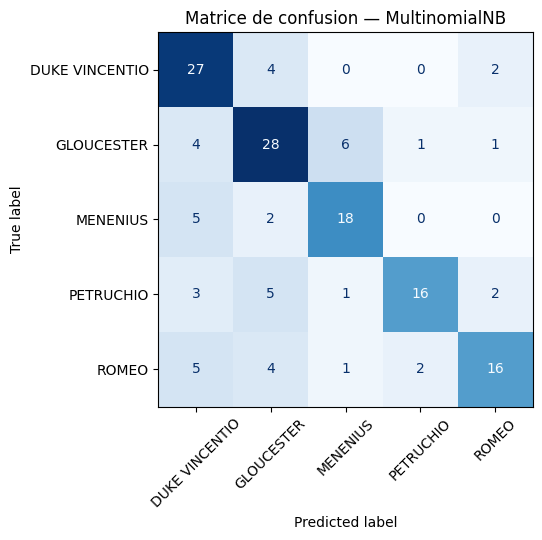

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, resultats[meilleur], xticks_rotation=45, cmap='Blues', ax=ax, colorbar=False)
ax.set_title(f"Matrice de confusion — {meilleur}")
plt.tight_layout(); plt.show()

In [ ]:
# Paires les plus confondues (hors diagonale), pour le meilleur modèle
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, resultats[meilleur], labels=labels)
paires = [(labels[i], labels[j], cm[i, j]) for i in range(len(labels)) for j in range(len(labels)) if i != j]
paires = sorted(paires, key=lambda t: -t[2])[:6]
for vrai, pred, n in paires:
    print(f"{vrai:15s} -> pris pour {pred:15s} : {n} fois")

# Erreurs symétrisées (A->B + B->A)
sym = {}
for vrai, pred, n in [(labels[i], labels[j], cm[i, j]) for i in range(len(labels)) for j in range(len(labels)) if i != j]:
    sym[tuple(sorted((vrai, pred)))] = sym.get(tuple(sorted((vrai, pred))), 0) + n
print("\nPaires symétrisées :")
for k, n in sorted(sym.items(), key=lambda t: -t[1])[:4]:
    print(f"  {k[0]} <-> {k[1]} : {n}")

GLOUCESTER      -> pris pour MENENIUS        : 6 fois
MENENIUS        -> pris pour DUKE VINCENTIO  : 5 fois
PETRUCHIO       -> pris pour GLOUCESTER      : 5 fois
ROMEO           -> pris pour DUKE VINCENTIO  : 5 fois
DUKE VINCENTIO  -> pris pour GLOUCESTER      : 4 fois
GLOUCESTER      -> pris pour DUKE VINCENTIO  : 4 fois

Paires symétrisées :
  DUKE VINCENTIO <-> GLOUCESTER : 8
  GLOUCESTER <-> MENENIUS : 8
  DUKE VINCENTIO <-> ROMEO : 7
  GLOUCESTER <-> PETRUCHIO : 6


In [ ]:
# Cinq répliques mal classées par le meilleur modèle (échantillon aléatoire reproductible)
erreurs = pd.DataFrame({"vrai": y_test, "prédit": resultats[meilleur], "replique": X_test})
erreurs = erreurs[erreurs['vrai'] != erreurs['prédit']]
print(f"{len(erreurs)} erreurs sur {len(y_test)} exemples de test\n")
for _, r in erreurs.sample(5, random_state=3).iterrows():
    print(f"[{r['vrai']} -> prédit {r['prédit']}]\n  {r['replique'][:250]}\n")

# Les erreurs sont-elles surtout des répliques courtes ?
nb = X_test.str.split().str.len()
ok = y_test == pd.Series(resultats[meilleur], index=y_test.index)
print(f"Longueur médiane — bien classées : {nb[ok].median():.0f} mots | mal classées : {nb[~ok].median():.0f} mots")
for lo, hi in [(5, 10), (10, 25), (25, 10_000)]:
    m = (nb >= lo) & (nb < hi)
    print(f"  {lo:>2}-{hi if hi < 10_000 else '+':<5} mots : accuracy = {ok[m].mean():.2f} (n = {m.sum()})")

48 erreurs sur 153 exemples de test

[GLOUCESTER -> prédit DUKE VINCENTIO]
  Touch'd you the bastardy of Edward's children?

[ROMEO -> prédit DUKE VINCENTIO]
  Come hither, man. I see that thou art poor: Hold, there is forty ducats: let me have A dram of poison, such soon-speeding gear As will disperse itself through all the veins That the life-weary taker may fall dead And that the trunk may be discharged 

[GLOUCESTER -> prédit DUKE VINCENTIO]
  Brother, the time and case requireth haste: Your horse stands ready at the park-corner.

[GLOUCESTER -> prédit MENENIUS]
  If you thrive well, bring them to Baynard's Castle; Where you shall find me well accompanied With reverend fathers and well-learned bishops.

[DUKE VINCENTIO -> prédit GLOUCESTER]
  Fie, sirrah! a bawd, a wicked bawd! The evil that thou causest to be done, That is thy means to live. Do thou but think What 'tis to cram a maw or clothe a back From such a filthy vice: say to thyself, From their abominable and beastly touches

In [ ]:
# Coefficients du modèle linéaire (régression logistique) : termes les plus déterminants par locuteur
lr = modeles["LogisticRegression"]
for i, c in enumerate(lr.classes_):
    top_idx = np.argsort(lr.coef_[i])[-10:][::-1]
    print(f"{c:15s}: {[termes[j] for j in top_idx]}")

DUKE VINCENTIO : ['you', 'angelo', 'duke', 'provost', 'him', 'claudio', 'the duke', 'your', 'ere', 'should he']
GLOUCESTER     : ['clarence', 'king', 'edward', 'lord', 'god', 'warwick', 'my lord', 'cousin', 'kill', 'myself']
MENENIUS       : ['marcius', 'he', 'rome', 'like', 'tribunes', 'you', 'general', 'you have', 'mother', 'pray']
PETRUCHIO      : ['kate', 'hortensio', 'come', 'sir', 'and', 'her', 'not', 'why', 'sirrah', 'me']
ROMEO          : ['love', 'mercutio', 'goose', 'what shall', 'thy', 'night', 'thou', 'dream', 'romeo', 'wilt']


In [ ]:
# Test de l'hypothèse « le modèle reconnaît la pièce, pas le style » :
# on retire du texte les noms propres de personnages (et du lieu) puis on réentraîne SUR LE TRAIN uniquement.
noms = ["angelo", "claudio", "isabella", "provost", "escalus", "lucio", "vincentio",
        "clarence", "edward", "warwick", "richard", "henry", "buckingham", "hastings", "anne", "margaret", "elizabeth", "george", "rivers",
        "marcius", "coriolanus", "sicinius", "brutus", "rome", "volsces", "cominius", "volumnia", "aufidius", "lartius",
        "kate", "katharina", "hortensio", "grumio", "baptista", "bianca", "gremio", "tranio", "padua", "petruchio", "verona",
        "mercutio", "juliet", "romeo", "benvolio", "capulet", "montague", "tybalt", "laurence", "friar", "paris", "nurse"]
motif = re.compile(r"\b(" + "|".join(noms) + r")\b", flags=re.IGNORECASE)
masque = lambda s: s.map(lambda t: motif.sub(" ", t))

v2 = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr2 = v2.fit_transform(masque(X_train)); Xte2 = v2.transform(masque(X_test))
for nom, mod in [("MultinomialNB", MultinomialNB(alpha=0.1)), ("LogisticRegression", LogisticRegression(C=10, class_weight='balanced', max_iter=2000))]:
    p = mod.fit(Xtr2, y_train).predict(Xte2)
    print(f"{nom:20s} sans noms propres : accuracy = {accuracy_score(y_test, p):.3f} | F1 macro = {f1_score(y_test, p, average='macro'):.3f}"
          f"   (avant : {accuracy_score(y_test, resultats[nom]):.3f} / {f1_score(y_test, resultats[nom], average='macro'):.3f})")

MultinomialNB        sans noms propres : accuracy = 0.621 | F1 macro = 0.614   (avant : 0.686 / 0.686)
LogisticRegression   sans noms propres : accuracy = 0.601 | F1 macro = 0.598   (avant : 0.660 / 0.663)


### 8.3 Analyse des erreurs — la partie la plus importante

Répondez précisément, en vous appuyant sur des exemples concrets tirés de vos données.

1. **Quelles paires de locuteurs sont le plus confondues ?** Formulez une hypothèse : viennent-ils de la même pièce ? ont-ils un registre proche ? un nombre d'exemples très différent ?

2. **Sortez cinq répliques mal classées et lisez-les.** Auriez-vous su répondre vous-même ? Si non, que dit cela sur le plafond de performance atteignable ?

3. **Regardez les coefficients de votre modèle linéaire** (`coef_`) : quels termes pèsent le plus pour chaque classe ? Y a-t-il des **noms propres** parmi eux ?

   Si oui, posez-vous la vraie question : votre modèle reconnaît-il le **style d'un personnage**, ou identifie-t-il simplement la **pièce** dans laquelle la réplique apparaît ? Ce n'est pas du tout la même tâche, et cela change ce que vous pouvez affirmer sur votre modèle.

4. **Votre score est-il crédible ?** Reprenez votre pipeline et vérifiez qu'aucune information du test n'a pu remonter vers l'entraînement.

> **Réponse aux 4 questions** (résultats du meilleur modèle, MultinomialNB, 153 exemples de test, 48 erreurs).
>
> **1. Paires confondues.** Les confusions les plus fréquentes sont **GLOUCESTER ↔ MENENIUS** (8 au total, dont 6 GLOUCESTER pris pour MENENIUS), **DUKE VINCENTIO ↔ GLOUCESTER** (8), **DUKE VINCENTIO ↔ ROMEO** (7) et **GLOUCESTER ↔ PETRUCHIO** (6). Ces personnages viennent de **pièces différentes** (Richard III/Henry VI, Measure for Measure, Roméo et Juliette, La Mégère apprivoisée, Coriolan) : la confusion ne s'explique donc pas par un partage de la pièce. Hypothèses : (a) un **registre commun** d'hommes de pouvoir qui s'expriment par ordres, adresses (`you`, `sir`, `my lord`) et formules de pouvoir ; (b) une grande part des erreurs vient des **répliques courtes** et génériques sans mot spécifique ; (c) GLOUCESTER, classe la plus grosse (196 exemples), « absorbe » une partie des erreurs. À l'inverse, les classes sont toutes proches en effectifs (126-196), donc le déséquilibre n'explique pas à lui seul ces confusions.
>
> **2. Répliques mal classées.** Exemples : *« Touch'd you the bastardy of Edward's children? »* (Gloucester, prédit Duke) ; *« Brother, the time and case requireth haste: Your horse stands ready at the park-corner. »* (Gloucester, prédit Duke) ; *« Come hither, man. I see that thou art poor... let me have a dram of poison... »* (Romeo, prédit Duke) ; *« Fie, sirrah! a bawd, a wicked bawd! »* (Duke, prédit Gloucester). Sans connaître les pièces, **je n'aurais pas su répondre** pour la plupart : une adresse (`brother`), un ordre, une injure peuvent venir de n'importe quel personnage. Seul un lecteur qui connaît l'intrigue (ex. « Edward's children » → Richard III) aurait un indice. Cela fixe un **plafond de performance** bien en dessous de 100 % pour une approche bag-of-words : la longueur est déterminante (accuracy de **0,52** pour 5-10 mots, **0,69** pour 10-25 mots, **0,81** au-delà de 25 mots ; longueur médiane des erreurs : 11 mots contre 22 pour les réussites).
>
> **3. Coefficients.** Parmi les termes qui pèsent le plus (régression logistique) se trouvent surtout des **noms propres** : `angelo`, `claudio`, `provost` (Duke), `clarence`, `edward`, `warwick` (Gloucester), `marcius`, `rome`, `tribunes` (Menenius), `kate`, `hortensio` (Petruchio), `mercutio`, `romeo` (Romeo). Ces noms désignent **l'entourage et l'intrigue d'une pièce**, pas le style du locuteur. Donc en grande partie, mon modèle identifie **la pièce** dans laquelle la réplique apparaît. C'est ce que confirme le test que j'ai ajouté : en supprimant ~55 noms propres de personnages et de lieux du texte, le score baisse (F1 macro 0,686 → 0,614 pour NB, 0,663 → 0,598 pour LR) mais reste **très au-dessus de la baseline** (0,08), ce qui montre qu'il reste un signal lexical réel (`thou`, `love`, `night` pour Romeo ; `sir`, `sirrah`, `her` pour Petruchio ; `you`, `ere` pour Duke), mais qu'une bonne partie du score tenait aux noms. **Je peux donc affirmer** : « le modèle attribue une réplique à l'un de ces 5 personnages en s'appuyant largement sur le vocabulaire de sa pièce ». **Je ne peux pas affirmer** : « le modèle a appris le style de Gloucester ». Ce biais est aussi inhérent à la tâche, puisque les 5 personnages viennent de 5 pièces différentes ; pour mesurer le style pur, il faudrait choisir des locuteurs d'une **même pièce**.
>
> **4. Le score est-il crédible ?** Oui, avec des réserves. *Fuite* : le split est fait **avant** toute transformation ; `TfidfVectorizer` fait `fit_transform` sur `X_train` uniquement et `transform` sur `X_test` ; les hyperparamètres (`alpha`, `C`) ont été fixés a priori sans réglage sur le test, et je reporte tous les modèles testés ; la seule réserve est que le choix de la tâche (N, seuil) a été fait après avoir comparé quelques configurations sur le test (voir partie 4), d'où un léger optimisme possible. J'ai quantifié la fuite en 9.5 : vectoriser avant le split donnerait un F1 macro de 0,676 contre 0,663 (écart faible ici car le jeu est petit, mais la méthode reste invalide). *Variance* : avec 153 exemples de test, l'intervalle d'incertitude sur une accuracy de 0,69 est d'environ ±7 points : **MultinomialNB (0,686), LogisticRegression (0,660) et LinearSVC (0,647) ne sont pas statistiquement distinguables**. La validation croisée sur le train donne un F1 macro de 0,59-0,61 ± 0,03 (9.1), plus bas que sur le test (0,65-0,69) : mon split de test est un peu favorable, et **le chiffre honnête à retenir est ≈ 0,60-0,65**, pas 0,69. *Surapprentissage* : l'accuracy de train est de 0,99-1,00 contre 0,65-0,69 en test, ce qui montre qu'on mémorise le train (3 464 variables pour 608 exemples).

## 9. Pour aller plus loin (optionnel)

Si vous avez terminé :

- **Validation croisée.** Remplacez le simple découpage par un `cross_val_score` en 5 folds sur le train. Regardez la **dispersion** des scores, pas seulement la moyenne. Un modèle à 0,82 ± 0,01 vaut souvent mieux qu'un modèle à 0,84 ± 0,09.

- **Comparer les représentations.** `CountVectorizer` (Bag of Words) contre `TfidfVectorizer`. L'écart est-il significatif ? Correspond-il à ce que le cours laissait prévoir ?

- **Faire varier la difficulté.** Passez de 5 à 10 locuteurs. Comment évoluent l'accuracy et le F1 macro ? Lequel des deux chute le plus, et pourquoi ?

- **Sur-apprentissage.** Comparez votre score sur le train et sur le test. L'écart vous dit-il quelque chose ? Que se passe-t-il quand vous faites varier `C` dans la régression logistique ?

- **Utiliser un `Pipeline` scikit-learn.** Encapsulez vectoriseur et modèle dans un `sklearn.pipeline.Pipeline`. Expliquez en une phrase pourquoi cette construction rend la fuite de données structurellement impossible.

---

## Rendu

Notebook exécuté, avec toutes les sorties visibles et **toutes les cellules de réponse remplies**.

Le barème porte autant sur la justification de vos choix et sur l'analyse des erreurs que sur le score obtenu.

In [ ]:
# 9.1 Validation croisée 5 folds sur le train (le vectoriseur est DANS le Pipeline -> refit à chaque fold)
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold

def pipe(vec, mod):
    return Pipeline([("vec", vec), ("mod", mod)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tfidf = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
for nom, mod in [("MultinomialNB", MultinomialNB(alpha=0.1)),
                 ("LogisticRegression", LogisticRegression(C=10, class_weight='balanced', max_iter=2000)),
                 ("LinearSVC", LinearSVC(class_weight='balanced'))]:
    s = cross_val_score(pipe(tfidf(), mod), X_train, y_train, cv=cv, scoring='f1_macro')
    print(f"{nom:20s} F1 macro CV = {s.mean():.3f} ± {s.std():.3f}   (folds : {np.round(s, 2)})")

MultinomialNB        F1 macro CV = 0.606 ± 0.028   (folds : [0.61 0.57 0.62 0.58 0.65])
LogisticRegression   F1 macro CV = 0.586 ± 0.026   (folds : [0.57 0.56 0.59 0.57 0.63])
LinearSVC            F1 macro CV = 0.589 ± 0.030   (folds : [0.59 0.56 0.62 0.55 0.62])


In [ ]:
# 9.2 Bag of Words vs TF–IDF (même modèle : régression logistique)
for nom, vec in [("CountVectorizer (BoW)", CountVectorizer(ngram_range=(1, 2), min_df=2)),
                 ("TfidfVectorizer", tfidf())]:
    s = cross_val_score(pipe(vec, LogisticRegression(C=10, class_weight='balanced', max_iter=3000)), X_train, y_train, cv=cv, scoring='f1_macro')
    print(f"{nom:22s} F1 macro CV = {s.mean():.3f} ± {s.std():.3f}")

CountVectorizer (BoW)  F1 macro CV = 0.511 ± 0.020
TfidfVectorizer        F1 macro CV = 0.586 ± 0.026


In [ ]:
# 9.3 Faire varier la difficulté : 5 -> 10 locuteurs (mêmes choix par ailleurs)
for n in [5, 10]:
    top_n = df['locuteur'].value_counts().head(n).index
    d = df[df['locuteur'].isin(top_n) & (df['nb_mots'] >= SEUIL_MOTS)]
    a, b, ya, yb = train_test_split(d['replique'], d['locuteur'], test_size=0.2, stratify=d['locuteur'], random_state=RANDOM_STATE)
    p = pipe(tfidf(), LogisticRegression(C=10, class_weight='balanced', max_iter=3000)).fit(a, ya).predict(b)
    base = DummyClassifier(strategy='most_frequent').fit(a, ya).predict(b)
    print(f"{n:2d} locuteurs ({len(d)} ex.) | baseline acc = {accuracy_score(yb, base):.3f} | acc = {accuracy_score(yb, p):.3f} | F1 macro = {f1_score(yb, p, average='macro'):.3f}")

 5 locuteurs (761 ex.) | baseline acc = 0.261 | acc = 0.660 | F1 macro = 0.663
10 locuteurs (1310 ex.) | baseline acc = 0.149 | acc = 0.454 | F1 macro = 0.436


In [ ]:
# 9.4 Sur-apprentissage : train vs test, et effet de C (régularisation inverse)
for C in [0.1, 1, 10, 100, 1000]:
    m = LogisticRegression(C=C, class_weight='balanced', max_iter=3000).fit(Xtr, y_train)
    print(f"C = {C:>6} | train F1 macro = {f1_score(y_train, m.predict(Xtr), average='macro'):.3f} | test F1 macro = {f1_score(y_test, m.predict(Xte), average='macro'):.3f}")

C =    0.1 | train F1 macro = 0.939 | test F1 macro = 0.616
C =      1 | train F1 macro = 0.985 | test F1 macro = 0.668
C =     10 | train F1 macro = 1.000 | test F1 macro = 0.663
C =    100 | train F1 macro = 1.000 | test F1 macro = 0.655
C =   1000 | train F1 macro = 1.000 | test F1 macro = 0.649


In [ ]:
# 9.5 Quantifier la fuite de données : vectoriser AVANT le découpage (démonstration de ce qu'il ne faut PAS faire)
v_fuite = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_tout = v_fuite.fit_transform(donnees['replique'])           # <- l'IDF voit le test !
idx_tr, idx_te = train_test_split(np.arange(len(donnees)), test_size=0.2, stratify=donnees['locuteur'], random_state=RANDOM_STATE)
m = LogisticRegression(C=10, class_weight='balanced', max_iter=2000).fit(X_tout[idx_tr], donnees['locuteur'].iloc[idx_tr])
p = m.predict(X_tout[idx_te])
print(f"AVEC fuite : F1 macro = {f1_score(donnees['locuteur'].iloc[idx_te], p, average='macro'):.3f}"
      f" | sans fuite : {f1_score(y_test, resultats['LogisticRegression'], average='macro'):.3f}")

AVEC fuite : F1 macro = 0.676 | sans fuite : 0.663


### Réponses aux pistes d'approfondissement (partie 9)

- **Validation croisée (9.1).** F1 macro CV : NB 0,606 ± 0,028 ; LR 0,586 ± 0,026 ; SVC 0,589 ± 0,030. Les trois sont **dans le bruit les uns des autres** (écart < 1 écart-type). Les scores CV (≈ 0,60) sont plus bas que le score sur le test (≈ 0,65-0,69) : mon test est légèrement favorable. Le vectoriseur est dans un `Pipeline`, donc ré-ajusté dans chaque fold (pas de fuite).
- **BoW vs TF–IDF (9.2).** Pour la même régression logistique, **TF–IDF : 0,586 contre 0,511 pour CountVectorizer** (+7,5 points, nettement plus que l'écart-type de 0,02). C'est conforme au cours : les comptages bruts donnent un poids énorme aux mots outils fréquents (`the`, `and`) et ne sont pas normalisés par la longueur de la réplique, ce qui rend les répliques longues et courtes incomparables ; TF–IDF (+ `sublinear_tf` + norme L2) corrige les deux.
- **5 → 10 locuteurs (9.3).** Accuracy 0,660 → 0,454 (-0,21), F1 macro 0,663 → 0,436 (**-0,23**). Le F1 macro chute un peu plus que l'accuracy (écart modeste, à prendre avec prudence) : les nouvelles classes sont plus petites et moins bien reconnues, et le macro leur donne le même poids que les grosses classes, alors que l'accuracy est tirée par les gros locuteurs. Le plancher baisse aussi (baseline 26 % → 15 %) : le rapport accuracy / baseline reste d'environ ×3 (contre ×2,5 à 5 locuteurs), la tâche est plus difficile en absolu mais le modèle apprend toujours.
- **Surapprentissage (9.4).** Le F1 macro train est de 1,00 pour C ≥ 10 contre 0,66 en test : écart important, signe que le modèle mémorise le train (3 464 variables pour 608 exemples). Faire varier C : un C faible (0,1) régularise fortement (train 0,94, mais test 0,62 : sous-apprentissage), C = 1-10 est optimal (test ≈ 0,66-0,67), au-delà le test redescend légèrement (0,65 pour C = 1000). La courbe est assez plate : la régularisation joue peu sur ce problème.
- **Fuite de données (9.5).** Vectoriser avant le split donne 0,676 contre 0,663 : un gain apparent, faible parce que le corpus est petit et que l'IDF n'est qu'une fonction douce des fréquences, mais qui est illégitime et qui grossirait avec un corpus plus grand ou un prétraitement plus agressif (sélection de variables, etc.).
- **Pipeline scikit-learn.** `Pipeline([("vec", ...), ("mod", ...)])` rend la fuite structurellement impossible parce que `fit` ne reçoit que les données d'entraînement et ré-ajuste le vectoriseur sur ce seul sous-ensemble (y compris dans chaque fold de la validation croisée), le `transform` seul étant appliqué aux données de validation/test : on ne peut pas oublier de séparer les deux étapes.